<a href="https://colab.research.google.com/github/arunreghunath25b-afk/Exit_Exam_Arun/blob/main/Exit_Exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, f1_score

In [36]:
df =pd.read_csv("/content/drive/MyDrive/DSA/Exit Exam/G2 (1).csv")

In [37]:
df.head()

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58


In [38]:
df.shape

(1351, 10)

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   object 
 6   type_2           765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 105.7+ KB


In [40]:
df.columns

Index(['id', 'name', 'height_dm', 'weight_hg', 'base_experience', 'type_1',
       'type_2', 'hp', 'attack', 'defense'],
      dtype='object')

In [41]:
df.nunique()

,0
id,1351
name,1351
height_dm,86
weight_hg,551
base_experience,201
type_1,18
type_2,18
hp,109
attack,131
defense,120


In [42]:
#Numeric Coloumns
num_cols = df.select_dtypes(
    include=np.number
).columns
print(num_cols)

Index(['id', 'height_dm', 'weight_hg', 'base_experience', 'hp', 'attack',
       'defense'],
      dtype='object')


In [43]:
#Categorical Coloumns
cat_cols = df.select_dtypes(
    include='object'
).columns
print(cat_cols)

Index(['name', 'type_1', 'type_2'], dtype='object')


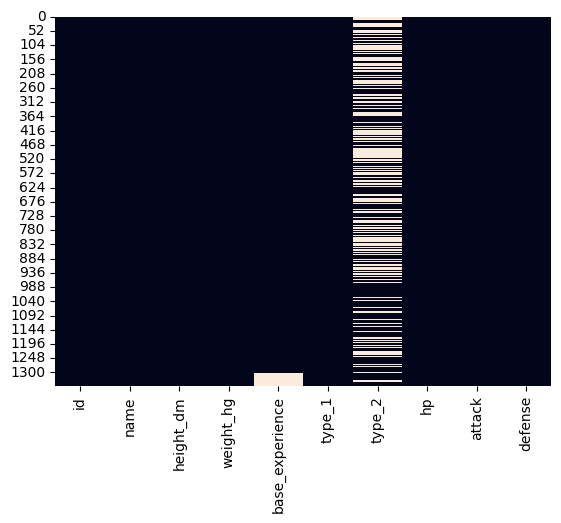

In [44]:
sns.heatmap(df.isnull(), cbar=False)
plt.show()

In [45]:
#Check for missing values and duplicates
df.isna().sum()

,0
id,0
name,0
height_dm,0
weight_hg,0
base_experience,49
type_1,0
type_2,586
hp,0
attack,0
defense,0


In [46]:
df.duplicated().sum()

np.int64(0)

Task 2 Data Preprocessing
Numeric features: median imputation + standard scaling (useful for Logistic Regression, SVM and KNN).
Categorical features: most-frequent imputation + one-hot encoding.
Tree models do not generally require scaling, but this shared pipeline keeps preprocessing consistent. If desired, create a separate no-scaling numeric transformer for tree models.

In [47]:
#Handle Missing value appropriately
df["base_experience"] = df["base_experience"].fillna(
    df["base_experience"].median()
)



In [48]:

df["type_2"] = df["type_2"].fillna("No secondary type")

In [49]:
print("\nAfter handling missing values:")
print(df.isnull().sum())



After handling missing values:
id                 0
name               0
height_dm          0
weight_hg          0
base_experience    0
type_1             0
type_2             0
hp                 0
attack             0
defense            0
dtype: int64


In [50]:
print("\nTotal missing values:", df.isnull().sum().sum())



Total missing values: 0


In [51]:
df["attack_class"] = pd.qcut(
    df["attack"],
    q=3,
    labels=["Low", "Medium", "High"]
)



In [52]:
X = df.drop(
    columns=["id", "name", "attack", "attack_class"]
)

y = df["attack_class"]



In [53]:
#Encode categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"),
        num_cols),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         cat_cols)
    ]
)

In [54]:
# Training Data And Test Data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [57]:
# Update num_cols and cat_cols to match the columns remaining in X_train
num_cols = [col for col in num_cols if col in X_train.columns]
cat_cols = [col for col in cat_cols if col in X_train.columns]

# Re-define the preprocessor with the correct columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

# Apply Encoding
X_train = preprocessor.fit_transform(X_train)

In [58]:
X_test = preprocessor.transform(X_test)

In [59]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining dataset:")
print(X_train[:5])

print("\nTesting dataset:")
print(X_test[:5])

print("\nPreprocessing completed successfully!")


X_train shape: (1080, 42)
X_test shape: (271, 42)
y_train shape: (1080,)
y_test shape: (271,)

Training dataset:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 35 stored elements and shape (5, 42)>
  Coords	Values
  (0, 0)	8.0
  (0, 1)	85.0
  (0, 2)	149.0
  (0, 3)	75.0
  (0, 4)	55.0
  (0, 14)	1.0
  (0, 23)	1.0
  (1, 0)	5.0
  (1, 1)	25.0
  (1, 2)	161.0
  (1, 3)	60.0
  (1, 4)	90.0
  (1, 14)	1.0
  (1, 23)	1.0
  (2, 0)	11.0
  (2, 1)	310.0
  (2, 2)	390.0
  (2, 3)	103.0
  (2, 4)	86.0
  (2, 17)	1.0
  (2, 23)	1.0
  (3, 0)	6.0
  (3, 1)	60.0
  (3, 2)	161.0
  (3, 3)	120.0
  (3, 4)	95.0
  (3, 17)	1.0
  (3, 23)	1.0
  (4, 0)	21.0
  (4, 1)	1350.0
  (4, 2)	175.0
  (4, 3)	120.0
  (4, 4)	80.0
  (4, 17)	1.0
  (4, 29)	1.0

Testing dataset:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 35 stored elements and shape (5, 42)>
  Coords	Values
  (0, 0)	11.0
  (0, 1)	970.0
  (0, 2)	142.0
  (0, 3)	75.0
  (0, 4)	85.0
  (0, 14)	1.0
  (0, 23)	1.0
  (1, 0)	4.0
  (1, 1)	203.0
  (1, 2)	60

Task 3 :Exploratory Data Analysis
Target distribution
A highly imbalanced target can make accuracy misleading. Inspect class counts and proportions. Decide whether precision, recall, F1, ROC-AUC or PR-AUC is most important based on the cost of false positives and false negatives.



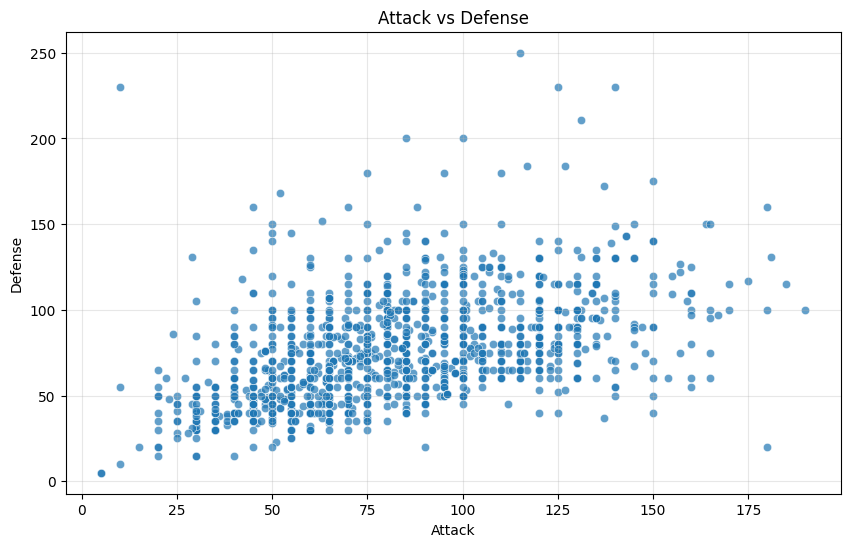

Correlation: 0.48117270823538505


In [60]:
#Attack vs Defence
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="attack",
    y="defense",
    alpha=0.7
)

plt.title("Attack vs Defense")
plt.xlabel("Attack")
plt.ylabel("Defense")
plt.grid(alpha=0.3)
plt.show()

# Correlation
print("Correlation:",
      df["attack"].corr(df["defense"]))


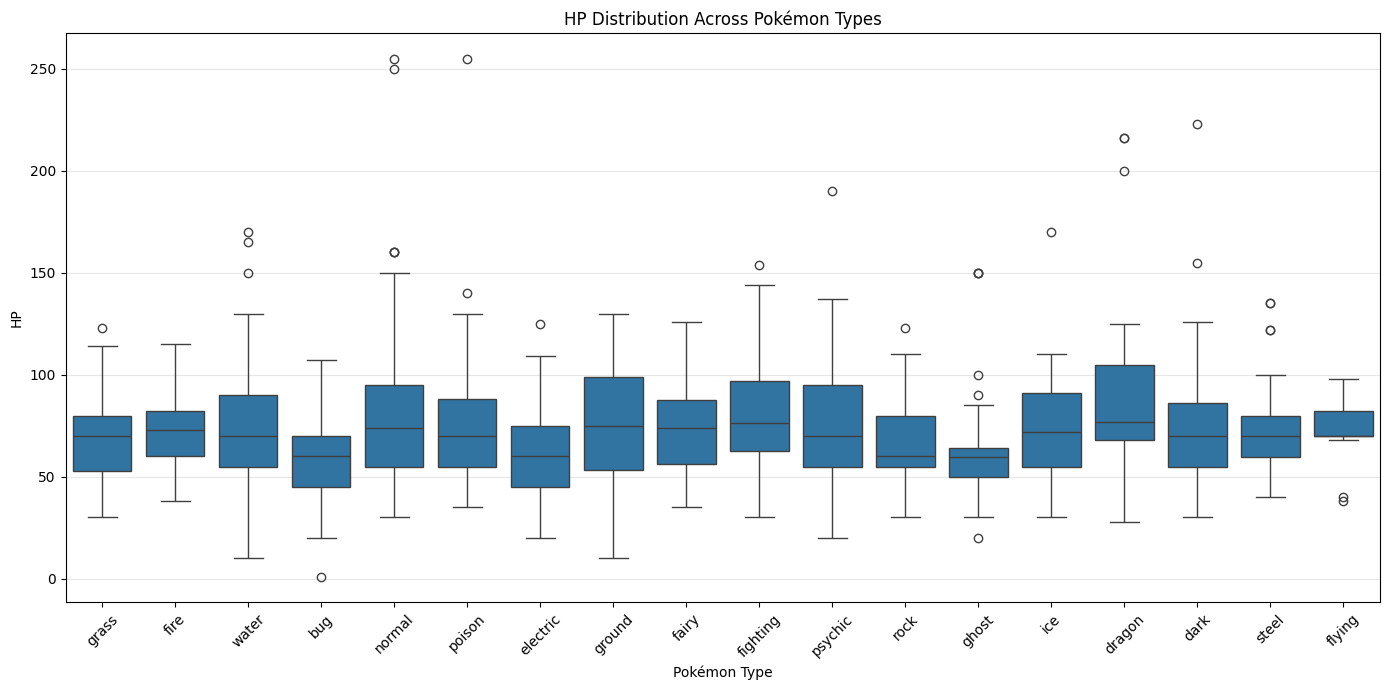

In [61]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="type_1",
    y="hp"
)

plt.title("HP Distribution Across Pokémon Types")
plt.xlabel("Pokémon Type")
plt.ylabel("HP")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

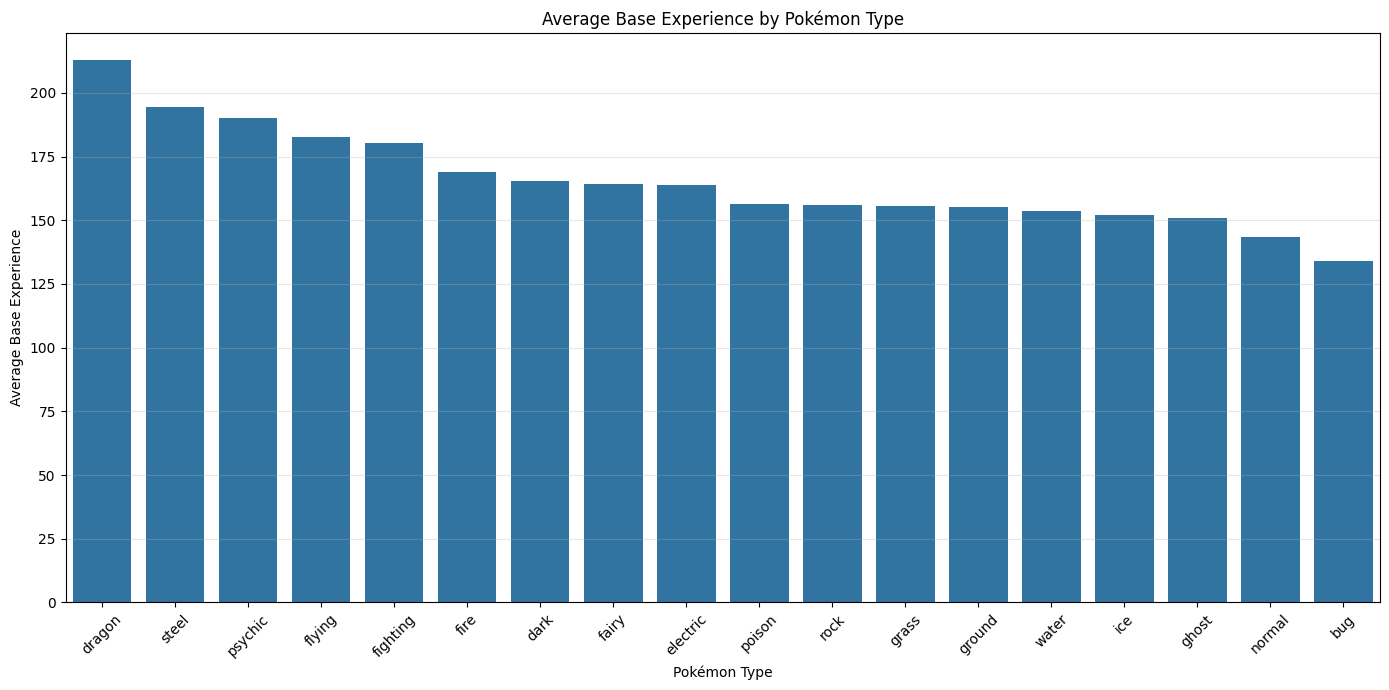

      type_1  base_experience
0     dragon       212.915254
1      steel       194.596154
2    psychic       190.174419
3     flying       182.769231
4   fighting       180.177419
5       fire       168.773810
6       dark       165.555556
7      fairy       164.200000
8   electric       163.990000
9     poison       156.519231
10      rock       156.024096
11     grass       155.426230
12    ground       155.100000
13     water       153.756250
14       ice       152.159091
15     ghost       150.903846
16    normal       143.417266
17       bug       133.852632


In [62]:

experience_by_type = (
    df.groupby("type_1")["base_experience"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=experience_by_type,
    x="type_1",
    y="base_experience"
)

plt.title("Average Base Experience by Pokémon Type")
plt.xlabel("Pokémon Type")
plt.ylabel("Average Base Experience")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(experience_by_type)


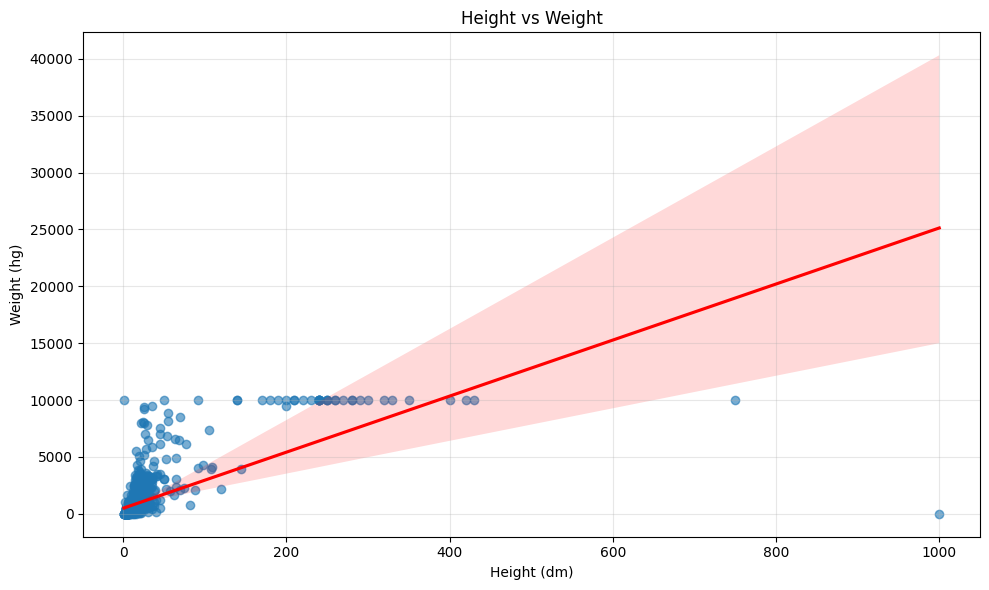

Height vs Weight Correlation: 0.6716213754423365


In [63]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="height_dm",
    y="weight_hg",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Height vs Weight")
plt.xlabel("Height (dm)")
plt.ylabel("Weight (hg)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Correlation
print(
    "Height vs Weight Correlation:",
    df["height_dm"].corr(df["weight_hg"])
)


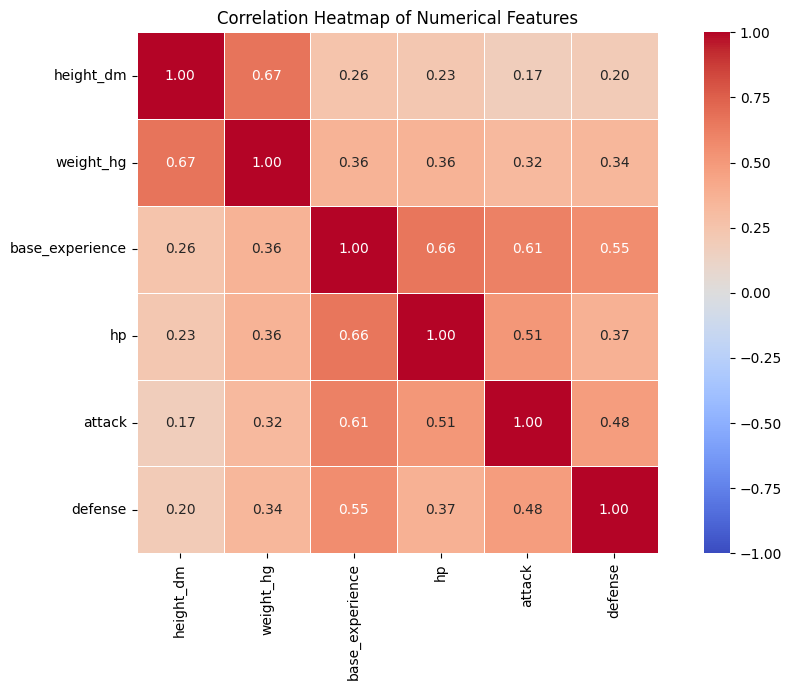

In [67]:
num_cols = [
    "height_dm",
    "weight_hg",
    "base_experience",
    "hp",
    "attack",
    "defense"
]

# Calculate correlation
correlation = df_clean[num_cols].corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


1. Dragon Pokemon Type should have the highest average attack and it si above 200

2. Height and weight may provide related information.
If they are highly correlated, there may be some redundancy between these features.
However, we should not automatically remove either feature.
Both can help Random Forest learn Pokémon characteristics.

3. Weight: May help distinguish heavier and lighter Pokémon.
Height: May help identify physical size patterns.
Attack: May help distinguish Pokémon with different battle characteristics.
Base Experience: May provide information about Pokémon strength and progression.
HP and Defense: May provide additional distinguishing information.


In [64]:


import pandas as pd

# Group-wise IQR outlier detection

hp_outliers = []

for pokemon_type, group in df.groupby("type_1"):

    Q1 = group["hp"].quantile(0.25)
    Q3 = group["hp"].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = group[
        (group["hp"] < lower_bound) |
        (group["hp"] > upper_bound)
    ]

    for _, row in outliers.iterrows():

        hp_outliers.append({
            "Pokemon": row["name"],
            "Type": pokemon_type,
            "HP": row["hp"],
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound
        })

# Display outliers
hp_outlier_df = pd.DataFrame(hp_outliers)

print("HP Outliers Within Each Pokemon Type:")
print(hp_outlier_df)

print("\nTotal HP Outliers:", len(hp_outlier_df))


HP Outliers Within Each Pokemon Type:
                Pokemon      Type   HP  Lower Bound  Upper Bound
0              shedinja       bug    1        7.500      107.500
1              guzzlord      dark  223        8.500      132.500
2               ting-lu      dark  155        8.500      132.500
3             regidrago    dragon  200       12.500      160.500
4      zygarde-complete    dragon  216       12.500      160.500
5          zygarde-mega    dragon  216       12.500      160.500
6           raging-bolt  electric  125       -0.625      120.375
7            iron-hands  fighting  154       11.375      148.375
8                noibat    flying   40       52.000      100.000
9              rookidee    flying   38       52.000      100.000
10              duskull     ghost   20       28.000       86.000
11             drifloon     ghost   90       28.000       86.000
12             drifblim     ghost  150       28.000       86.000
13     giratina-altered     ghost  150       28.000 

/tmp/ipykernel_6112/2817615711.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(cap_hp_outliers)


Original HP Outliers: 0

Original HP Summary:
count    1351.000000
mean       71.673575
std        26.827529
min         1.000000
25%        55.000000
50%        70.000000
75%        85.000000
max       255.000000
Name: hp, dtype: float64

HP Summary After Capping:
count    1351.000000
mean       70.956236
std        24.021957
min         7.500000
25%        55.000000
50%        70.000000
75%        85.000000
max       160.500000
Name: hp, dtype: float64

Total HP Values Capped: 34

Capped HP Values:
                     name    type_1  hp_original       hp
112               chansey    normal          250  155.000
142               snorlax    normal          160  155.000
201             wobbuffet   psychic          190  155.000
241               blissey    normal          255  155.000
291              shedinja       bug            1    7.500
320               wailord     water          170  142.875
354               duskull     ghost           20   28.000
424              drifloon     

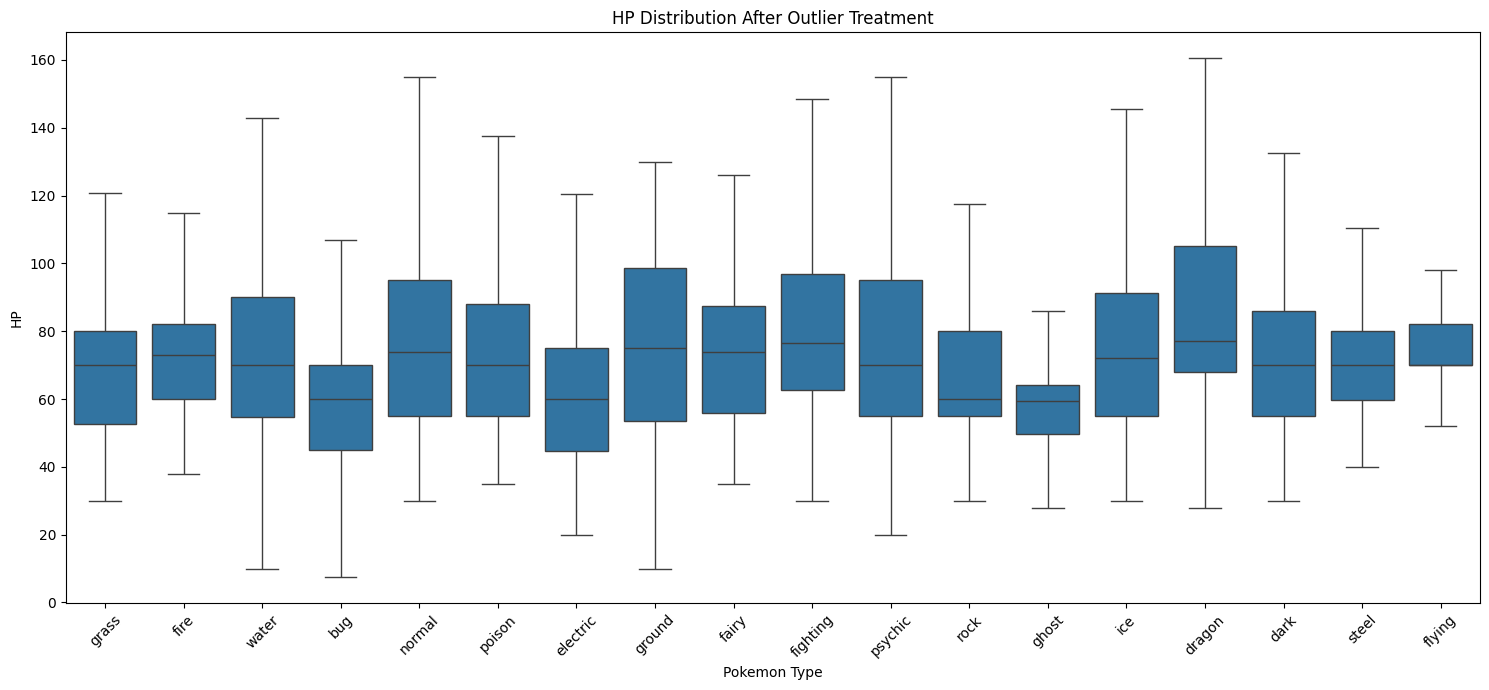

In [66]:

# Create a copy of original dataset
df_clean = df.copy()

# Store original HP values
df_clean["hp_original"] = df_clean["hp"]

# Function to calculate and cap outliers
def cap_hp_outliers(group):

    Q1 = group["hp"].quantile(0.25)
    Q3 = group["hp"].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    group["hp"] = group["hp"].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    return group


# Apply capping separately for each Pokémon type
df_clean = (
    df_clean.groupby("type_1", group_keys=False)
    .apply(cap_hp_outliers)
)

# Compare before and after
print("Original HP Outliers:",
      (df["hp"] != df["hp"]).sum())

print("\nOriginal HP Summary:")
print(df["hp"].describe())

print("\nHP Summary After Capping:")
print(df_clean["hp"].describe())

# Check changed values
changed = df_clean[df_clean["hp"] != df_clean["hp_original"]]

print("\nTotal HP Values Capped:", len(changed))

print("\nCapped HP Values:")
print(changed[["name", "type_1", "hp_original", "hp"]])

# Final boxplot
plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df_clean,
    x="type_1",
    y="hp"
)

plt.title("HP Distribution After Outlier Treatment")
plt.xlabel("Pokemon Type")
plt.ylabel("HP")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [68]:

from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd


selector = SelectKBest(score_func=f_classif, k=10)


X_train_selected = selector.fit_transform(X_train, y_train)


X_test_selected = selector.transform(X_test)


feature_names = preprocessor.get_feature_names_out()
selected_features = feature_names[selector.get_support()]

print("Selected Features:")
print(selected_features)

print("\nOriginal number of features:", X_train.shape[1])
print("Selected number of features:", X_train_selected.shape[1])


Selected Features:
['num__height_dm' 'num__weight_hg' 'num__base_experience' 'num__hp'
 'num__defense' 'cat__type_1_fighting' 'cat__type_2_No secondary type'
 'cat__type_2_dark' 'cat__type_2_dragon' 'cat__type_2_fighting']

Original number of features: 42
Selected number of features: 10


In [69]:

from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Create Random Forest estimator
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


rfe = RFE(
    estimator=rf,
    n_features_to_select=10
)


rfe.fit(X_train, y_train)


X_train_rfe = rfe.transform(X_train)
X_test_rfe = rfe.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
rfe_features = feature_names[rfe.support_]

print("RFE Selected Features:")
print(rfe_features)

print("\nOriginal Features:", X_train.shape[1])
print("Selected Features:", X_train_rfe.shape[1])


RFE Selected Features:
['num__height_dm' 'num__weight_hg' 'num__base_experience' 'num__hp'
 'num__defense' 'cat__type_1_fighting' 'cat__type_1_psychic'
 'cat__type_1_water' 'cat__type_2_No secondary type' 'cat__type_2_flying']

Original Features: 42
Selected Features: 10


                          Feature  Importance
2            num__base_experience    0.166652
1                  num__weight_hg    0.153184
3                         num__hp    0.135318
0                  num__height_dm    0.128136
4                    num__defense    0.125554
10           cat__type_1_fighting    0.019559
22              cat__type_1_water    0.017484
23  cat__type_2_No secondary type    0.016973
20               cat__type_1_rock    0.012565
31             cat__type_2_flying    0.012200


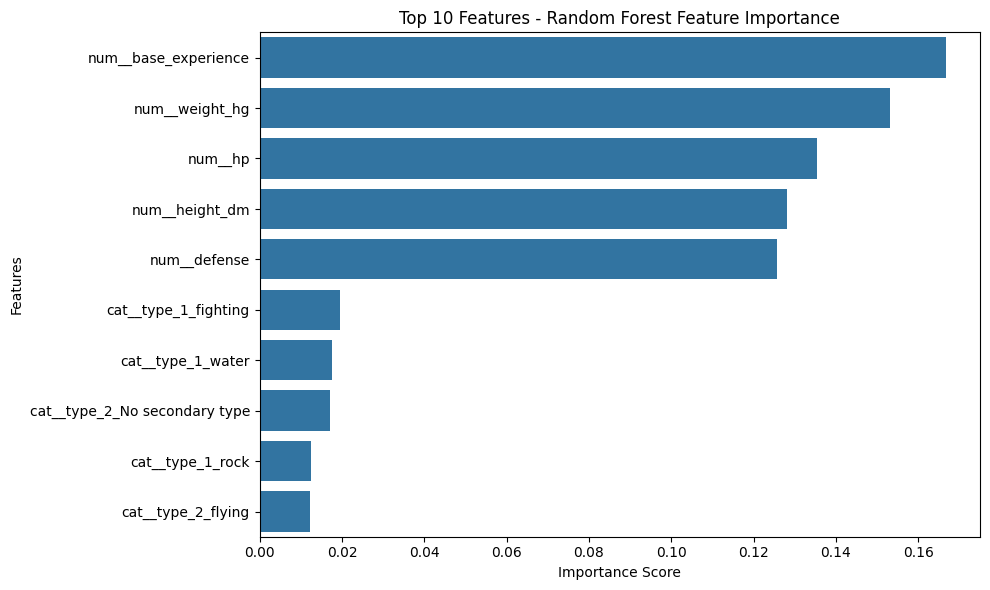

In [70]:

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Calculate feature importance
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
print(importance_df.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features - Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [71]:

# Select top 10 features from Random Forest importance
top_10_features = importance_df.head(10)["Feature"].tolist()

# Get their column positions
selected_indices = [
    list(feature_names).index(feature)
    for feature in top_10_features
]

# Create selected datasets
X_train_final = X_train[:, selected_indices]
X_test_final = X_test[:, selected_indices]

print("Original features:", X_train.shape[1])
print("Selected features:", X_train_final.shape[1])

print("\nSelected feature names:")
print(top_10_features)


Original features: 42
Selected features: 10

Selected feature names:
['num__base_experience', 'num__weight_hg', 'num__hp', 'num__height_dm', 'num__defense', 'cat__type_1_fighting', 'cat__type_1_water', 'cat__type_2_No secondary type', 'cat__type_1_rock', 'cat__type_2_flying']


In [ ]:
Task 4: Model Building
Start with Logistic Regression, Decision Tree and Random Forest. You may add KNN, SVM or Extra Trees when appropriate. For imbalanced classes, try class_weight="balanced" for models that support it.

The example below uses weighted F1 for general multiclass/binary comparison. For a business-critical binary class, choose the positive class and compare its precision/recall/F1 or PR-AUC rather than relying only on weighted averages.

In [77]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
import pandas as pd


models = {
    "Logistic Regression": models["Logistic Regression"],
    "KNN": models["KNN"],
    "Decision Tree": models["Decision Tree"],
    "Random Forest": models["Random Forest"],
    "SVM": models["SVM"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for model_name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    results.append({
        "Model": model_name,
        "Mean F1 Score": scores.mean(),
        "Standard Deviation": scores.std()
    })


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean F1 Score",
    ascending=False
)

print(results_df.round(4))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

                 Model  Mean F1 Score  Standard Deviation
3        Random Forest         0.6385              0.0383
0  Logistic Regression         0.6045              0.0294
2        Decision Tree         0.5872              0.0140
1                  KNN         0.5545              0.0289
4                  SVM         0.4901              0.0169


In [78]:

from sklearn.ensemble import RandomForestClassifier

best_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)


best_model.fit(X_train, y_train)


y_train_pred = best_model.predict(X_train)

print("Random Forest model training completed!")
print("Training predictions generated successfully.")


Random Forest model training completed!
Training predictions generated successfully.


In [79]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold


rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)


param_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 6],
    "max_features": ["sqrt", "log2"]
}


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(random_search.best_score_, 4))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20}

Best Cross-Validation F1 Score:
0.657


In [80]:

best_rf_model = random_search.best_estimator_

best_rf_model.fit(X_train, y_train)

print("Tuned Random Forest model trained successfully!")


Tuned Random Forest model trained successfully!


evaluation on test data

In [81]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_test_pred = best_rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

print("FINAL TEST EVALUATION")
print("---------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


FINAL TEST EVALUATION
---------------------
Accuracy : 0.6863
Precision: 0.6817
Recall   : 0.6825
F1 Score : 0.6806

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.75      0.70        88
         Low       0.84      0.79      0.81        96
      Medium       0.55      0.51      0.53        87

    accuracy                           0.69       271
   macro avg       0.68      0.68      0.68       271
weighted avg       0.69      0.69      0.69       271



1. Random Forest
It combines multiple decision trees to make predictions.
It can learn complex, non-linear relationships.
It handles different feature patterns effectively.
It generally reduces overfitting compared with a single decision tree.
It performed best in your previous model comparison.

2. The diagonal values represent correctly predicted Pokémon types.
Values outside the diagonal represent misclassifications.
The types with the highest misclassified counts are the most frequently misclassified.
3. Different Pokémon types can have similar HP, attack, and defense values.

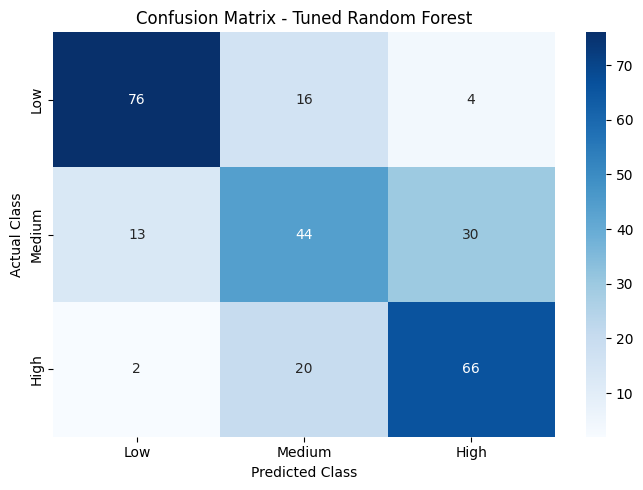

In [82]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [84]:

import pickle

# Save the trained model and preprocessor together
model_data = {
    "model": best_rf_model,
    "preprocessor": preprocessor,
    "features": X_train.columns.tolist() if hasattr(X_train, "columns") else None
}

with open("random_forest_model.pkl", "wb") as file:
    pickle.dump(model_data, file)

print("Model saved successfully as random_forest_model.pkl")


Model saved successfully as random_forest_model.pkl


In [85]:

from IPython.display import FileLink, display

display(FileLink("random_forest_model.pkl"))


/content/random_forest_model.pkl

In [86]:

import pickle

with open("random_forest_model.pkl", "rb") as file:
    model_data = pickle.load(file)

model = model_data["model"]
preprocessor = model_data["preprocessor"]

print("Model loaded successfully!")


Model loaded successfully!


In [87]:

import os

print("File exists:", os.path.exists("random_forest_model.pkl"))
print("File size:", os.path.getsize("random_forest_model.pkl") if os.path.exists("random_forest_model.pkl") else "File not found")


File exists: True
File size: 5179889


In [88]:

from google.colab import files

files.download("random_forest_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Task 5 Flask web Application
1. Developers can explore how attributes such as HP, attack, defense, height, and weight relate to Pokémon types.

 It can provide a suggested type for newly designed Pokémon based on their statistics.

 Developers can study relationships between Pokémon types and their battle statistics.

 Players can estimate a Pokémon's primary type using its statistics.

 Players can explore how Pokémon characteristics differ across types.
Beginners can understand the relationship between Pokémon attributes and types.

 Players can experiment with different HP, attack, defense, height, weight, and base experience values to see the model's predictions.

 2. Prediction accuracy,Limited input Features,Similar Characteristics,Unseen pokemon

